# K-Means

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [3]:

from sklearn.datasets import make_blobs

In [4]:
X,y = make_blobs(
    n_samples=1000,
    centers=3,
    n_features=2,
    random_state=42
)

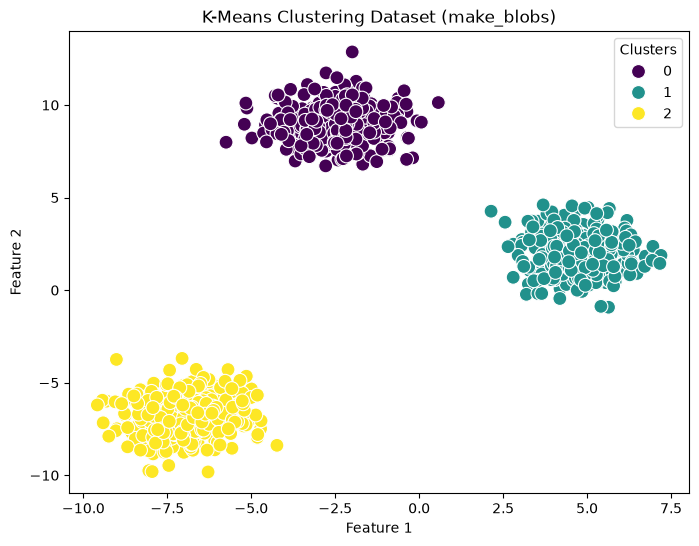

In [15]:
df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])
df['Cluster'] = y
# Visualize
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Feature1',
    y='Feature2',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title('K-Means Clustering Dataset (make_blobs)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(title='Clusters')
plt.show()


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [17]:
# train-test-split
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.3,random_state=42
)

In [18]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
from sklearn.cluster import KMeans

In [20]:
# ELBOW method - select optimal k value
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k,init='k-means++')
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

wcss

[1400.0000000000005,
 439.9498948056905,
 45.53331360570866,
 38.51218528129792,
 33.2113820713211,
 31.881639636990084,
 24.99399199468352,
 22.55403216994464,
 20.206123406476152,
 19.897401491317638]

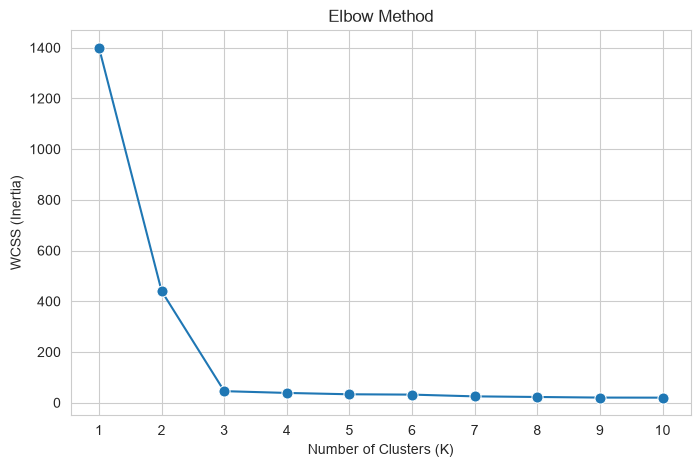

In [25]:
sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))
sns.lineplot(
    x=range(1, 11),
    y=wcss,
    marker='o',
    markersize=8
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()


In [26]:
kmeans = KMeans(n_clusters=3,init='k-means++')

In [27]:
kmeans.fit_predict(X_train_scaled)

array([0, 0, 0, 1, 2, 2, 0, 0, 2, 2, 2, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       2, 2, 1, 1, 2, 1, 0, 0, 2, 0, 2, 1, 0, 2, 2, 1, 2, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 2, 1, 0, 1, 1, 2, 0, 1, 1, 0, 1, 0, 0, 0, 1, 2,
       1, 2, 2, 0, 0, 0, 1, 2, 2, 1, 2, 2, 1, 0, 0, 1, 0, 2, 0, 1, 0, 2,
       1, 2, 0, 2, 2, 2, 2, 1, 0, 0, 0, 2, 2, 0, 0, 2, 1, 1, 2, 0, 1, 2,
       0, 0, 0, 0, 0, 0, 2, 1, 1, 1, 1, 0, 2, 1, 1, 0, 1, 1, 0, 2, 1, 2,
       1, 2, 0, 1, 1, 0, 0, 2, 1, 0, 1, 0, 1, 0, 1, 2, 2, 1, 1, 2, 1, 2,
       2, 1, 2, 1, 2, 0, 2, 2, 1, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 0, 2,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 2, 2, 2, 2, 0, 2, 2, 2, 1, 0,
       0, 0, 2, 0, 0, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1, 2, 0, 0, 2, 0, 2, 0,
       2, 1, 0, 0, 1, 1, 0, 1, 2, 2, 1, 2, 1, 2, 1, 0, 0, 0, 1, 2, 1, 1,
       0, 0, 0, 2, 2, 1, 0, 2, 0, 0, 2, 1, 0, 2, 2, 1, 1, 1, 0, 0, 2, 2,
       2, 2, 0, 1, 2, 0, 1, 0, 0, 0, 2, 1, 0, 0, 1, 0, 2, 1, 1, 0, 1, 1,
       2, 2, 0, 0, 1, 0, 1, 0, 2, 1, 2, 2, 1, 2, 1,

In [29]:
y_pred = kmeans.predict(X_test_scaled)

<Axes: >

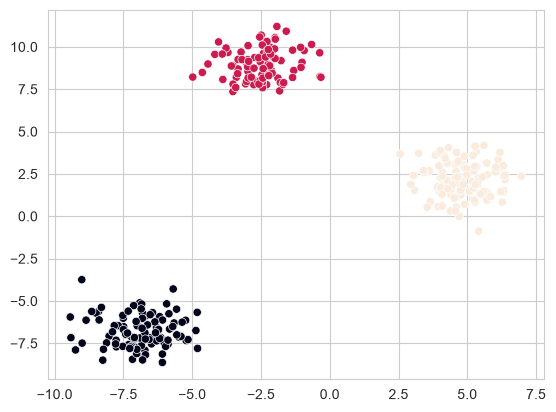

In [32]:
sns.scatterplot(
    x=X_test[:,0],
    y=X_test[:,1],
    c=y_pred
)

# Validating the k value
1. kneeLocator
2. Silhoutee scoring

In [36]:
from kneed import KneeLocator

kl=KneeLocator(range(1,11),wcss,curve='convex',direction='decreasing')

In [38]:
kl.elbow

np.int64(3)

In [39]:
# Silhoutee scoring
from sklearn.metrics import silhouette_score

In [40]:
silhoutee_coefficients = []
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,init='k-means++')
    kmeans.fit(X_train_scaled)
    score=silhouette_score(X_train_scaled,kmeans.labels_)
    silhoutee_coefficients.append(score)

silhoutee_coefficients

[0.6867964692302869,
 0.8421639000152684,
 0.6783551920410814,
 0.6706690040674904,
 0.499862674691352,
 0.33905636146215157,
 0.33550863507783735,
 0.3409518638855755,
 0.3215567604608032]

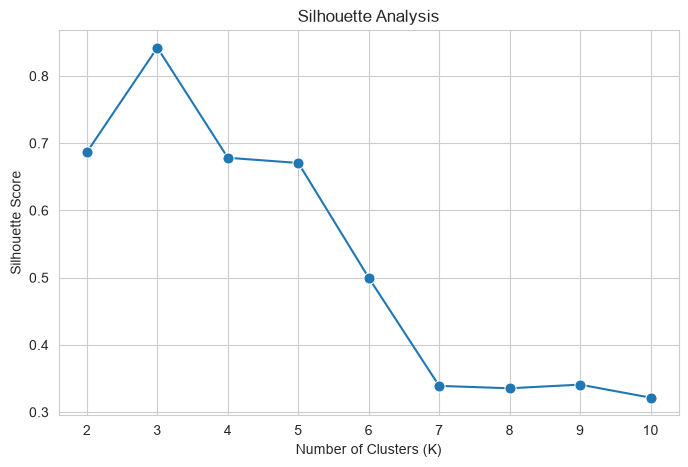

In [43]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    x=range(2, 11),
    y=silhoutee_coefficients,
    marker='o',
    markersize=8
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(range(2, 11))
plt.show()